# 1.3. PHÂN TÍCH ĐƠN BIẾN VÀ HAI BIẾN — THỰC HÀNH
**Sinh viên:** Bùi Nhật Hào — **MSSV:** 3124411077  
**Nguồn:** *Lab - Phan tich kham pha du lieu.pdf*, mục 1.3.2, 1.3.3 và 1.3.4, trang 9–18.  
**Trọng tâm:** SweetViz và AutoViz trên dữ liệu Marketing Campaign.

> Hãy chạy `On_tap_ly_Thuyet.ipynb` để xem 7 câu hỏi lý thuyết trước; notebook này thực hiện phần code và đánh giá.


## B. 1.3.2 — Bài làm mẫu theo PDF
### B1. Chuẩn bị môi trường, vị trí dữ liệu
Chỉ sử dụng dữ liệu thật từ nguồn PDF/Kaggle/GitHub. **Không phát sinh dữ liệu giả để điền vào báo cáo**.

In [2]:
from pathlib import Path
import urllib.request
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

# Tự tìm thư mục gốc khi mở notebook từ thư mục dự án hoặc trong Jupyter.
BASE = Path.cwd()
if not (BASE / "README_Huong_dan.txt").exists():
    BASE = BASE.parent
DATA = BASE / "data"
REPORTS = BASE / "Reports"
FIGS = BASE / "figures"
for folder in [DATA, REPORTS, FIGS]:
    folder.mkdir(parents=True, exist_ok=True)
sns.set_theme(style="whitegrid")
print("Project:", BASE.resolve())

def ensure_csv(filename, url):
    path = DATA / filename
    if path.exists():
        print("Dữ liệu có sẵn:", filename)
        return path
    try:
        print("Thử tải dữ liệu công khai:", filename)
        urllib.request.urlretrieve(url, path.with_suffix(path.suffix + ".tmp"))
        path.with_suffix(path.suffix + ".tmp").replace(path)
        print("Đã tải:", path)
    except Exception as e:
        print("Không tự tải được", filename, "- tải thủ công vào data/. Lỗi:", str(e)[:150])
    return path if path.exists() and path.stat().st_size > 10 else None

penguin_path = ensure_csv("penguins_size.csv", "https://raw.githubusercontent.com/dickoa/penguins/master/data/penguins_size.csv")
marketing_path = ensure_csv("marketing_campaign.csv", "https://raw.githubusercontent.com/sanathNU/Customer-Personality-Analysis/main/marketing_campaign.csv")

Project: E:\Lab05\PhanTichKhamPhaDuLieu\1_3_BuiNhatHao_3124411077
Dữ liệu có sẵn: penguins_size.csv
Dữ liệu có sẵn: marketing_campaign.csv


### B2. Phân tích đơn biến: Penguins (Histogram, bar chart, pie chart)
Dữ liệu gồm ba loài chim cánh cụt. `culmen_length_mm` là chiều dài mỏ; `species` là loài. **Lưu ý:** giữ luôn `sex` để có thể thực hiện bảng crosstab ở phần phân tích hai biến — PDF bị thiếu cột này trong bước lọc.

Số dòng/cột: (344, 7)


,species,culmen_length_mm,body_mass_g,sex
0,Adelie,39.1,3750.0,MALE
1,Adelie,39.5,3800.0,FEMALE
2,Adelie,40.3,3250.0,FEMALE
3,Adelie,NaN,NaN,NaN
4,Adelie,36.7,3450.0,FEMALE


Thiếu dữ liệu:


,Missing
species,0
culmen_length_mm,2
body_mass_g,2
sex,10


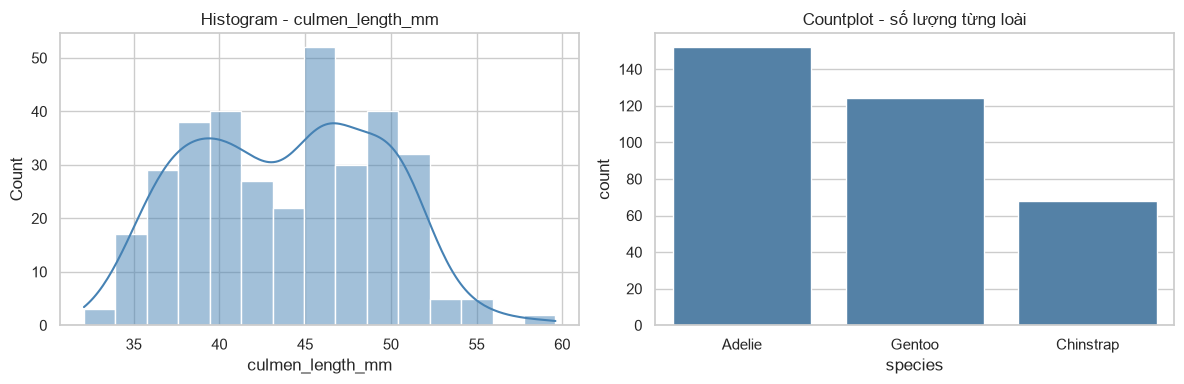

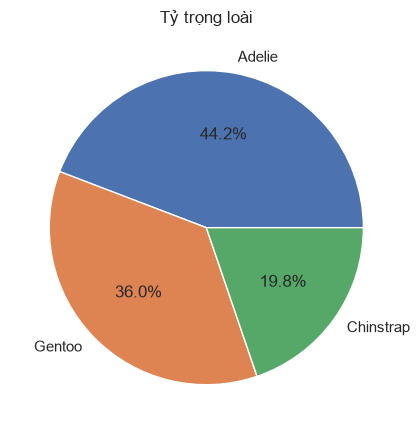

In [3]:
if penguin_path is not None:
    penguins = pd.read_csv(penguin_path)
    print("Số dòng/cột:", penguins.shape)
    display(penguins[["species","culmen_length_mm","body_mass_g","sex"]].head())
    print("Thiếu dữ liệu:")
    display(penguins[["species","culmen_length_mm","body_mass_g","sex"]].isna().sum().to_frame("Missing"))

    fig,axs=plt.subplots(1,2,figsize=(12,4))
    sns.histplot(data=penguins,x="culmen_length_mm",bins=15,kde=True,ax=axs[0],color="steelblue")
    axs[0].set_title("Histogram - culmen_length_mm")
    sns.countplot(data=penguins,x="species",ax=axs[1],order=penguins["species"].value_counts().index,color="steelblue")
    axs[1].set_title("Countplot - số lượng từng loài")
    plt.tight_layout();plt.savefig(FIGS/"1_3_penguin_univariate.png",dpi=140);plt.show()
    plt.figure(figsize=(5.5,4.5))
    penguins["species"].value_counts().plot.pie(autopct="%1.1f%%",ylabel="",title="Tỷ trọng loài")
    plt.tight_layout();plt.savefig(FIGS/"1_3_penguin_pie.png",dpi=140);plt.show()
else:
    print("Bỏ qua phần Penguins: vui lòng bổ sung data/penguins_size.csv rồi chạy lại.")

### B3. Phân tích đơn biến: dữ liệu giá nhà Amsterdam (boxplot, violin, describe)
Tải file **`HousingPricesData.csv`** từ [Kaggle Amsterdam house price](https://www.kaggle.com/datasets/thomasnibb/amsterdam-house-price-prediction) vào `data/`. Không thay bằng tập dữ liệu khác nếu muốn bám đúng đề. Nếu thiếu file, ô sau sẽ **bỏ qua có thông báo**.

In [4]:
house_path = DATA / "HousingPricesData.csv"
if house_path.exists():
    house = pd.read_csv(house_path)
    house = house[["Zip","Price","Area","Room"]].copy()
    house["Price"] = pd.to_numeric(house["Price"],errors="coerce")
    print("Thống kê mô tả giá nhà:")
    display(house[["Price","Area","Room"]].describe())
    fig,axs=plt.subplots(2,1,figsize=(10,6))
    sns.boxplot(data=house,x="Price",ax=axs[0],color="steelblue");axs[0].set_title("Boxplot giá nhà")
    sns.violinplot(data=house,x="Price",ax=axs[1],color="steelblue");axs[1].set_title("Violin plot giá nhà")
    plt.tight_layout();plt.savefig(FIGS/"1_3_house_univariate.png",dpi=140);plt.show()
else:
    print("Chưa có data/HousingPricesData.csv. Tải theo link Kaggle trong ô Markdown trên.")

Chưa có data/HousingPricesData.csv. Tải theo link Kaggle trong ô Markdown trên.


### B4. Phân tích hai biến: Penguins (scatterplot, crosstab, pivot table, pairplot)
Scatterplot đánh giá quan hệ chiều dài mỏ–khối lượng. `crosstab` đếm số con theo loài × giới tính (hai biến phân loại); `pivot_table` trung bình chiều dài mỏ theo loài; pairplot xem quan hệ nhiều cặp biến. Không suy luận nhân quả từ biểu đồ.

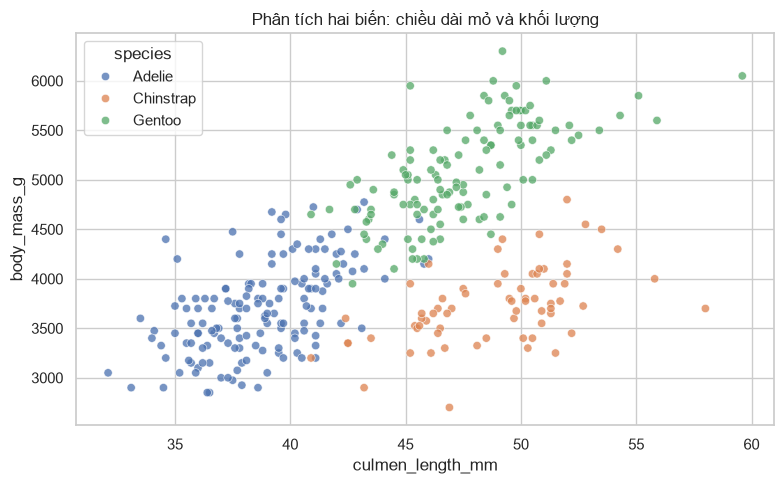

Crosstab loài × giới tính:


sex,.,FEMALE,MALE,NaN
species,,,,
Adelie,0,73,73,6
Chinstrap,0,34,34,0
Gentoo,1,58,61,4


Pivot trung bình chiều dài mỏ theo loài:


,culmen_length_mm
species,
Adelie,38.791391
Chinstrap,48.833824
Gentoo,47.504878


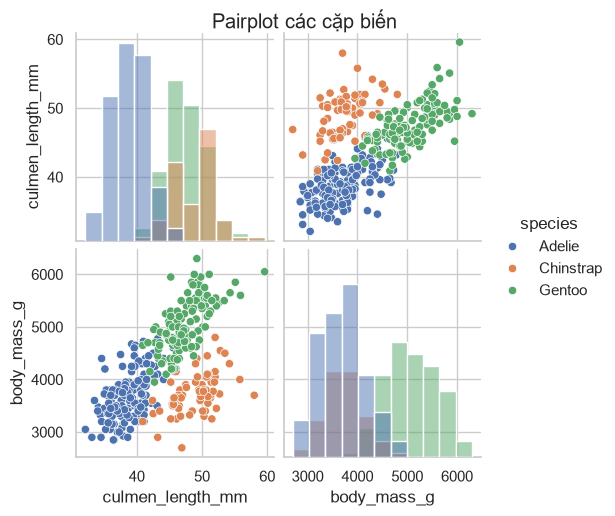

In [5]:
if penguin_path is not None:
    p_clean = penguins.dropna(subset=["culmen_length_mm", "body_mass_g"]).copy()
    plt.figure(figsize=(8,5))
    sns.scatterplot(data=p_clean,x="culmen_length_mm",y="body_mass_g",hue="species",alpha=.76)
    plt.title("Phân tích hai biến: chiều dài mỏ và khối lượng")
    plt.tight_layout();plt.savefig(FIGS/"1_3_penguin_bivariate.png",dpi=140);plt.show()
    print("Crosstab loài × giới tính:")
    display(pd.crosstab(index=penguins["species"],columns=penguins["sex"],dropna=False))
    print("Pivot trung bình chiều dài mỏ theo loài:")
    display(pd.pivot_table(penguins,values="culmen_length_mm",index="species",aggfunc="mean"))
    pair = sns.pairplot(data=penguins[["species","culmen_length_mm","body_mass_g"]].dropna(),hue="species",diag_kind="hist")
    pair.figure.suptitle("Pairplot các cặp biến",y=1.02)
    pair.figure.savefig(FIGS/"1_3_penguin_pairplot.png",dpi=130,bbox_inches="tight")
    plt.show()
else:
    print("Bỏ qua phân tích Penguins vì chưa có CSV.")

### B5. Ví dụ EDA tự động trong PDF: YData Profiling và D-Tale (tùy chọn)
Đây là **bài làm mẫu 1.3.2** trên trang 16–17, không phải hai bài tập bắt buộc của Hào. Mã được giữ ở dạng tùy chọn để tránh khởi động server D-Tale ngoài ý muốn. Để chạy, mở phần chú thích trong ô dưới.

In [6]:
# Khi muốn chạy ví dụ YData Profiling (tùy chọn), bỏ dấu # các dòng:
# %pip install ydata-profiling
# from ydata_profiling import ProfileReport
# if marketing_path is not None:
#     marketing_temp = pd.read_csv(marketing_path, sep="\t")
#     profile = ProfileReport(marketing_temp, title="Marketing Campaign - YData Profiling", minimal=True)
#     profile.to_file(REPORTS / "ydata_profile_output.html")

# Khi muốn chạy ví dụ D-Tale (tùy chọn, khởi động web server ở localhost):
# %pip install dtale
# import dtale
# if marketing_path is not None:
#     dtale.show(pd.read_csv(marketing_path, sep="\t"), open_browser=True)
print("Phần YData Profiling / D-Tale là mẫu tùy chọn: mặc định không chạy.")

Phần YData Profiling / D-Tale là mẫu tùy chọn: mặc định không chạy.


## C. Chuẩn bị dữ liệu Marketing Campaign cho hai bài thực hành
**Nguồn:** [Customer Personality Analysis](https://www.kaggle.com/datasets/imakash3011/customer-personality-analysis). Tệp gốc có **2.240 khách hàng × 29 thuộc tính**, `Income` thiếu **24** giá trị. Tệp CSV ngăn cột bằng **TAB (`\t`)**, phải đọc `sep="\t"`.

**Nguyên tắc:** giữ dữ liệu gốc để đối chiếu; chỉ nội suy giá trị thiếu trên bản sao phục vụ biểu đồ. Không tự thay thiếu bằng 0 (có thể làm sai thu nhập trung bình).

In [7]:
marketing = None
if marketing_path is not None:
    marketing = pd.read_csv(marketing_path,sep="\t")
    if marketing.shape[1] == 1:
        raise ValueError("CSV chỉ có 1 cột. Phải đọc marketing_campaign.csv với sep='\\t'.")
    print(f"Rows: {marketing.shape[0]:,} | Columns: {marketing.shape[1]}")
    display(marketing.head())
    display(marketing.isna().sum().sort_values(ascending=False).head(8).to_frame("Missing"))
    print("Bản ghi trùng lặp:", int(marketing.duplicated().sum()))
    print("Thống kê một số biến:")
    display(marketing[["Income","Recency","NumWebPurchases","NumStorePurchases","Response"]].describe().round(2))
else:
    print("Cần tải data/marketing_campaign.csv để làm bài SweetViz và AutoViz.")

Rows: 2,240 | Columns: 29


,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,...,NumWebVisitsMonth,AcceptedCmp3,AcceptedCmp4,AcceptedCmp5,AcceptedCmp1,AcceptedCmp2,Complain,Z_CostContact,Z_Revenue,Response
0,5524,1957,Graduation,Single,58138.0,0,0,04-09-2012,58,635,...,7,0,0,0,0,0,0,3,11,1
1,2174,1954,Graduation,Single,46344.0,1,1,08-03-2014,38,11,...,5,0,0,0,0,0,0,3,11,0
2,4141,1965,Graduation,Together,71613.0,0,0,21-08-2013,26,426,...,4,0,0,0,0,0,0,3,11,0
3,6182,1984,Graduation,Together,26646.0,1,0,10-02-2014,26,11,...,6,0,0,0,0,0,0,3,11,0
4,5324,1981,PhD,Married,58293.0,1,0,19-01-2014,94,173,...,5,0,0,0,0,0,0,3,11,0


,Missing
Income,24
ID,0
Year_Birth,0
Education,0
Marital_Status,0
Kidhome,0
Teenhome,0
Dt_Customer,0


Bản ghi trùng lặp: 0
Thống kê một số biến:


,Income,Recency,NumWebPurchases,NumStorePurchases,Response
count,2216.00,2240.00,2240.00,2240.00,2240.00
mean,52247.25,49.11,4.08,5.79,0.15
std,25173.08,28.96,2.78,3.25,0.36
min,1730.00,0.00,0.00,0.00,0.00
25%,35303.00,24.00,2.00,3.00,0.00
50%,51381.50,49.00,4.00,5.00,0.00
75%,68522.00,74.00,6.00,8.00,0.00
max,666666.00,99.00,27.00,13.00,1.00


### C1. Đơn biến trên Marketing: histogram, barplot, boxplot
Thu nhập lệch phải và có ngoại lệ (`max = 666666`). Ưu tiên trình bày median và IQR khi diễn giải; biểu đồ hộp có thể bị ảnh hưởng bởi giá trị cực lớn. Có thể cắt trục biểu đồ *chỉ để quan sát* (không xóa dòng gốc).

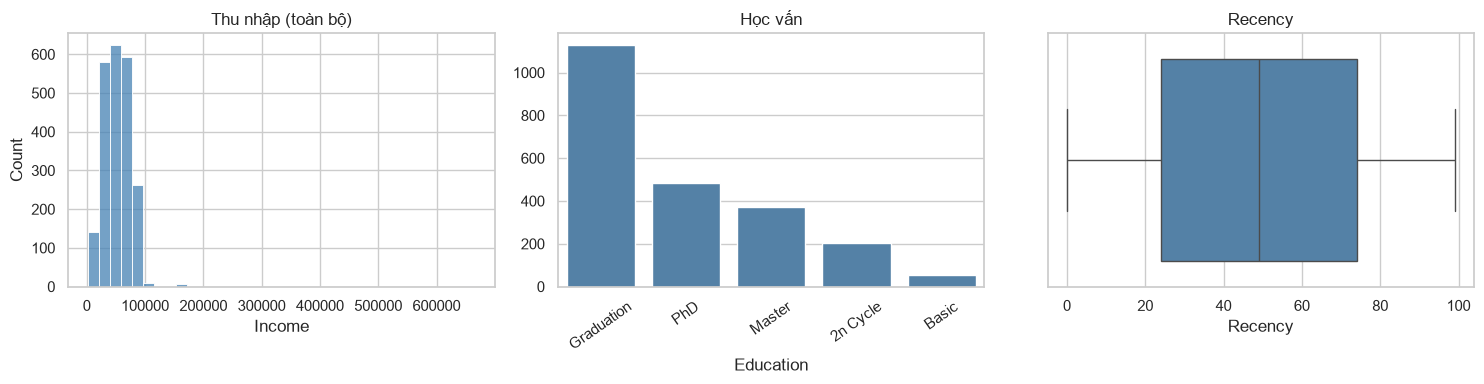

Income mean vs median: 52247.25135379061 51381.5


In [8]:
if marketing is not None:
    fig,axs=plt.subplots(1,3,figsize=(15,4))
    sns.histplot(data=marketing,x="Income",bins=35,ax=axs[0],color="steelblue");axs[0].set_title("Thu nhập (toàn bộ)")
    edu=marketing["Education"].value_counts();sns.barplot(x=edu.index,y=edu.values,ax=axs[1],color="steelblue");axs[1].tick_params(axis="x",rotation=35);axs[1].set_title("Học vấn")
    sns.boxplot(data=marketing,x="Recency",ax=axs[2],color="steelblue");axs[2].set_title("Recency")
    plt.tight_layout();plt.savefig(FIGS/"1_3_marketing_univariate.png",dpi=140);plt.show()
    print("Income mean vs median:", marketing["Income"].mean(), marketing["Income"].median())

### C2. Hai biến trên Marketing: scatterplot, crosstab, pivot, correlation/heatmap
Vì `Response` là nhị phân (0/1), bảng chéo cho thấy số khách phản hồi theo học vấn; pivot cho biết thu nhập trung bình theo tình trạng hôn nhân (chỉ tính dòng không thiếu). Heatmap dùng riêng các biến số, tương quan **không phải** quan hệ nhân quả.

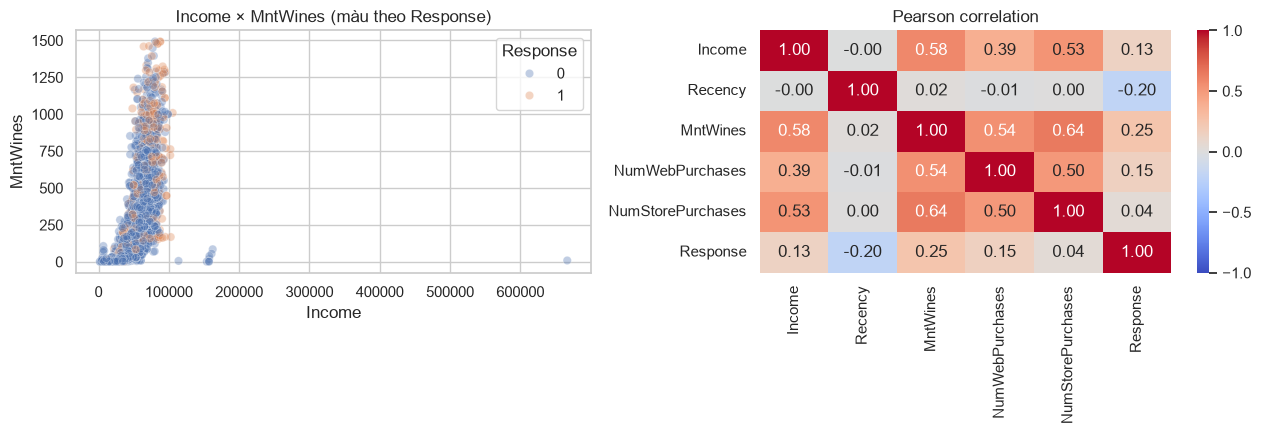

Crosstab Education × Response:


Response,0,1
Education,,
2n Cycle,181,22
Basic,52,2
Graduation,975,152
Master,313,57
PhD,385,101


Pivot Thu nhập trung bình theo hôn nhân:


,Income
Marital_Status,
Absurd,72365.50
Alone,43789.00
Divorced,52834.23
Married,51724.98
Single,50995.35
Together,53245.53
Widow,56481.55
YOLO,48432.00


In [9]:
if marketing is not None:
    fig,axs=plt.subplots(1,2,figsize=(13,4.5))
    sns.scatterplot(data=marketing,x="Income",y="MntWines",hue="Response",alpha=.35,ax=axs[0])
    axs[0].set_title("Income × MntWines (màu theo Response)")
    subcols=["Income","Recency","MntWines","NumWebPurchases","NumStorePurchases","Response"]
    sns.heatmap(marketing[subcols].corr(numeric_only=True),annot=True,fmt=".2f",cmap="coolwarm",ax=axs[1],vmin=-1,vmax=1)
    axs[1].set_title("Pearson correlation")
    plt.tight_layout();plt.savefig(FIGS/"1_3_marketing_bivariate.png",dpi=140);plt.show()
    print("Crosstab Education × Response:")
    display(pd.crosstab(marketing["Education"],marketing["Response"]))
    print("Pivot Thu nhập trung bình theo hôn nhân:")
    display(pd.pivot_table(marketing,values="Income",index="Marital_Status",aggfunc="mean").round(2))

## D. 1.3.3 — BÀI TẬP THỰC HÀNH 1: SWEETVIZ
**Yêu cầu trong PDF:** *Tìm hiểu các tính năng và cách sử dụng SweetViz trên Marketing Campaign*.

**Chức năng:** Sinh báo cáo EDA HTML từ DataFrame: số dòng/cột, missing, loại dữ liệu, phân bố, liên hệ từng đặc trưng với nhãn `Response`, liên hệ giữa các biến. Có thể so sánh hai tập hoặc hai nhóm đối tượng.

**Điểm cần kiểm chứng sau khi chạy:** mở `Reports/SweetViz_Marketing.html` và xem Overview, Associations, Income, Response. Ghi lại số thiếu, phân bố Response và các quan sát hợp lệ. Chụp ảnh màn hình cho báo cáo Word.

**Nguồn API:** https://pypi.org/project/sweetviz/ (`sv.analyze(..., target_feat="Response")` + `.show_html(..., open_browser=False)`).

In [10]:
if marketing is None:
    print("CHƯA CHẠY SweetViz: thiếu dữ liệu. Tải CSV theo README rồi chạy lại.")
else:
    try:
        import sweetviz as sv
        # Bỏ ID (mã định danh), và cột hằng số để tránh biểu đồ ít ý nghĩa.
        sw_df = marketing.drop(columns=["ID","Z_CostContact","Z_Revenue"],errors="ignore").copy()
        report = sv.analyze(sw_df, target_feat="Response")
        sweetviz_html = REPORTS / "SweetViz_Marketing.html"
        report.show_html(filepath=str(sweetviz_html), open_browser=False)
        print("ĐÃ TẠO:", sweetviz_html.resolve())
    except ImportError as exc:
        print("CHƯA CHẠY SweetViz: cần cài 'pip install sweetviz'. Chi tiết:", exc)
    except Exception as exc:
        print("SweetViz lỗi trong môi trường này (hãy chụp thông báo để xử lý):",repr(exc))

c:\Users\Lenovo\miniconda3\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Feature: Response (TARGET)                   |▎         | [  4%]   00:00 -> (00:00 left)findfont: Failed to find font weight normal for Roboto, now using 500.
findfont: Failed to find font weight normal for Roboto, now using 500.
findfont: Failed to find font weight normal for Roboto, now using 500.
findfont: Failed to find font weight normal for Roboto, now using 500.
Feature: Year_Birth                          |▋         | [  7%]   00:00 -> (00:04 left)findfont: Failed to find font weight normal for Roboto, now using 500.
findfont: Failed to find font weight normal for Roboto, now using 500.
findfont: Failed to find font weight normal for Roboto, now using 500.
findfont: Failed to find font weight normal for Roboto, now using 500.
findfo

Report e:\Lab05\PhanTichKhamPhaDuLieu\1_3_BuiNhatHao_3124411077\Reports\SweetViz_Marketing.html was generated.
ĐÃ TẠO: E:\Lab05\PhanTichKhamPhaDuLieu\1_3_BuiNhatHao_3124411077\Reports\SweetViz_Marketing.html


### D2. Phân tích kết quả SweetViz — viết báo cáo sau khi xuất HTML
- **Overview:** 2.240 dòng, 29 cột trước bước bỏ ID/cột hằng; 24 missing ở `Income`.
- **Target Response:** 334 khách (`14.91%`) có Response=1; 1.906 khách (`85.09%`) có Response=0. Đây là mất cân đối lớp, không đánh đồng với độ chính xác mô hình.
- **Income:** mean xấp xỉ 52.247; median xấp xỉ 51.382; có giá trị cực đại 666.666 cần khảo sát nguồn dữ liệu, không tự gán sai.
- **Association:** chỉ rút kết luận về mối liên hệ khi thấy biểu đồ/giá trị cụ thể, không kết luận quan hệ nhân quả.

> Các con số trên lấy từ CSV nguồn công khai. **Kết quả tương tác trong HTML phải chạy và đối chiếu lại trên máy bạn.**

## E. 1.3.4 — BÀI TẬP THỰC HÀNH 2: AUTOVIZ
**Yêu cầu trong PDF:** *Tìm hiểu tính năng và cách sử dụng AutoViz trên Marketing Campaign*.

**Chức năng:** tự xác định dạng biến để vẽ nhiều biểu đồ EDA (phân bố, quan hệ giữa biến số/phân loại, liên hệ với target); có chế độ lưu hình qua `verbose=2` và `chart_format="svg"`. Dùng một nhóm cột đại diện để hình rõ hơn, tránh đồ thị quá dày.

**Nguồn API:** https://pypi.org/project/autoviz/. Hỗ trợ `AV.AutoViz(filename="", dfte=DataFrame, depVar="Response", verbose=2, chart_format="svg", save_plot_dir=...)`.

In [11]:
if marketing is None:
    print("CHƯA CHẠY AutoViz: thiếu data/marketing_campaign.csv")
else:
    try:
        from autoviz import AutoViz_Class
        cols = ["Year_Birth","Education","Marital_Status","Income","Kidhome","Teenhome",
                "Recency","MntWines","MntMeatProducts","NumWebPurchases","NumStorePurchases","Response"]
        auto_df = marketing[cols].copy()
        # Chỉ dùng bản sao cho biểu đồ; dùng median không bóp méo bởi outlier như mean.
        auto_df["Income"] = auto_df["Income"].fillna(auto_df["Income"].median())
        av = AutoViz_Class()
        av_result = av.AutoViz(filename="",sep=",",depVar="Response",dfte=auto_df,
                 header=0,verbose=2,lowess=False,chart_format="svg",
                 max_rows_analyzed=5000,max_cols_analyzed=20,
                 save_plot_dir=str(REPORTS / "AutoViz_Plots"))
        print("ĐÃ CHẠY AutoViz. Kiểm tra thư mục:", (REPORTS/"AutoViz_Plots").resolve())
        print("Dữ liệu trả về:", getattr(av_result,"shape",type(av_result)))
    except ImportError as exc:
        print("CHƯA CHẠY AutoViz: pip install autoviz. Chi tiết:", exc)
    except Exception as exc:
        print("AutoViz lỗi trong môi trường này (hãy kiểm tra phiên bản thư viện):",repr(exc))

Imported v0.1.905. Please call AutoViz in this sequence:
    AV = AutoViz_Class()
    %matplotlib inline
    dfte = AV.AutoViz(filename, sep=',', depVar='', dfte=None, header=0, verbose=1, lowess=False,
               chart_format='svg',max_rows_analyzed=150000,max_cols_analyzed=30, save_plot_dir=None)
Shape of your Data Set loaded: (2240, 12)
#######################################################################################
######################## C L A S S I F Y I N G  V A R I A B L E S  ####################
#######################################################################################
Classifying variables in data set...
  Printing up to 30 columns (max) in each category:
    Numeric Columns : ['Income']
    Integer-Categorical Columns: ['Year_Birth', 'Kidhome', 'Teenhome', 'Recency', 'MntWines', 'MntMeatProducts', 'NumWebPurchases', 'NumStorePurchases']
    String-Categorical Columns: ['Education', 'Marital_Status']
    Factor-Categorical Columns: []
    String-Boole

,Data Type,Missing Values%,Unique Values%,Minimum Value,Maximum Value,DQ Issue
Year_Birth,int64,0.000000,2,1893.000000,1996.000000,Column has 3 outliers greater than upper bound (2004.00) or lower than lower bound(1932.00). Cap them or remove them.
Education,object,0.000000,0,,,No issue
Marital_Status,object,0.000000,0,,,"3 rare categories: ['Alone', 'Absurd', 'YOLO']. Group them into a single category or drop the categories."
Income,float64,0.000000,NA,1730.000000,666666.000000,Column has 8 outliers greater than upper bound (117053.62) or lower than lower bound(-13109.38). Cap them or remove them.
Kidhome,int64,0.000000,0,0.000000,2.000000,No issue
Teenhome,int64,0.000000,0,0.000000,2.000000,No issue
Recency,int64,0.000000,4,0.000000,99.000000,No issue
MntWines,int64,0.000000,37,0.000000,1493.000000,Column has 33 outliers greater than upper bound (1225.50) or lower than lower bound(-698.50). Cap them or remove them.
MntMeatProducts,int64,0.000000,27,0.000000,1725.000000,Column has 174 outliers greater than upper bound (549.75) or lower than lower bound(-304.25). Cap them or remove them.
NumWebPurchases,int64,0.000000,0,0.000000,27.000000,Column has 4 outliers greater than upper bound (12.00) or lower than lower bound(-4.00). Cap them or remove them.


All Plots are saved in e:\Lab05\PhanTichKhamPhaDuLieu\1_3_BuiNhatHao_3124411077\Reports\AutoViz_Plots\Response
Time to run AutoViz = 42 seconds 
ĐÃ CHẠY AutoViz. Kiểm tra thư mục: E:\Lab05\PhanTichKhamPhaDuLieu\1_3_BuiNhatHao_3124411077\Reports\AutoViz_Plots
Dữ liệu trả về: (2240, 12)


### E2. Đọc và đối chiếu biểu đồ AutoViz
1. Kiểm tra các hình phân bố cho `Income`, `Recency`, `MntWines` và số lượng theo `Education`/`Response`.
2. Xem các biểu đồ scatter/association giữa `Income` và `MntWines`, hoặc `NumWebPurchases` với `NumStorePurchases`.
3. Xác nhận tiền xử lý: AutoViz dùng **bản sao có điền median cho 24 Income thiếu**; SweetViz ở phần D dùng bản **chưa điền**, nên kết quả thiếu và vài thống kê có thể khác nhau.
4. Ảnh chụp/số liệu trong thư mục AutoViz_Plots là minh chứng thực hành; đừng khẳng định có ảnh nếu chương trình chưa sinh file.

## F. Tổng kết & checklist bàn giao
**Kết quả kiểm tra sơ bộ từ Marketing Campaign gốc:** 2.240 hàng × 29 cột; 24 giá trị thiếu `Income`; Education: Graduation 1.127, PhD 486, Master 370, 2n Cycle 203, Basic 54; Response=1 là 334/2.240 (14,91%).

**So sánh công cụ:** SweetViz phù hợp làm một **báo cáo HTML tương tác thống nhất**, dễ xem thống kê từng đặc trưng và liên hệ với target. AutoViz phù hợp **tự động tạo loạt hình** và có thể lưu SVG để chèn Word. Cả hai là công cụ thăm dò; không thay thế việc kiểm tra chất lượng dữ liệu hoặc phép suy luận nhân quả.

**Trước khi gửi nhóm trưởng:**
- [ ] Cài thư viện và chạy tất cả ô bắt buộc từ đầu đến cuối.
- [ ] Có dữ liệu `marketing_campaign.csv` thật và đúng `sep="\t"`.
- [ ] Mở được `SweetViz_Marketing.html`.
- [ ] Có biểu đồ trong `AutoViz_Plots`.
- [ ] Chụp hai ảnh minh chứng và cập nhật vào Word.
- [ ] Lưu notebook với output rồi chuyển nhóm trưởng ghép thành 4 notebook theo kế hoạch.

**Nguồn:** hai PDF giảng viên; Kaggle Marketing Campaign, Penguins, Amsterdam Housing; PyPI SweetViz và AutoViz.